In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, roc_curve

In [2]:
df = fetch_openml("credit-g", version=1, as_frame=True).frame
df.head()


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
print(df.shape)
print(df["class"].value_counts())
df.info()

(1000, 21)
class
good    700
bad     300
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_paymen

In [4]:
df["target"] = (df["class"] == "good").astype(int)
df = df.drop(columns="class")

In [5]:
df["credit_per_month"] = df["credit_amount"] / df["duration"]
df["credit_to_age"] = df["credit_amount"] / df["age"]
df["long_duration"] = (df["duration"] > 24).astype(int)

In [6]:
X = df.drop(columns="target")
y = df["target"]

num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(len(X_train), len(X_test))

800 200


In [8]:
model = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model.fit(X_train, y_train)

pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, pred))
print("ROC-AUC:", roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

           0       0.47      0.70      0.56        60
           1       0.84      0.66      0.74       140

    accuracy                           0.68       200
   macro avg       0.65      0.68      0.65       200
weighted avg       0.73      0.68      0.69       200

ROC-AUC: 0.7611904761904762


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
}

scores = {}
probas = {}
for name, clf in models.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    probas[name] = p
    scores[name] = roc_auc_score(y_test, p)
    print("\n", name)
    print(classification_report(y_test, pipe.predict(X_test)))
    print("ROC-AUC:", round(scores[name], 3))


 Logistic Regression
              precision    recall  f1-score   support

           0       0.47      0.70      0.56        60
           1       0.84      0.66      0.74       140

    accuracy                           0.68       200
   macro avg       0.65      0.68      0.65       200
weighted avg       0.73      0.68      0.69       200

ROC-AUC: 0.761

 Decision Tree
              precision    recall  f1-score   support

           0       0.42      0.73      0.54        60
           1       0.83      0.57      0.68       140

    accuracy                           0.62       200
   macro avg       0.63      0.65      0.61       200
weighted avg       0.71      0.62      0.64       200

ROC-AUC: 0.669

 Random Forest
              precision    recall  f1-score   support

           0       0.62      0.40      0.48        60
           1       0.78      0.89      0.83       140

    accuracy                           0.74       200
   macro avg       0.70      0.65      0.66 

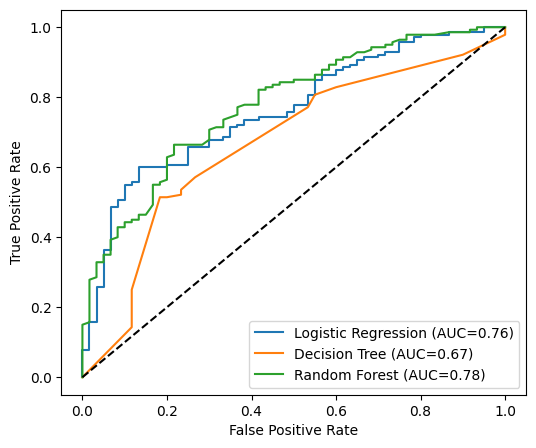

In [10]:
plt.figure(figsize=(6, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={scores[name]:.2f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.savefig("roc_curves.png", dpi=150)
plt.show()